# ComplaintLens: Routing and Theme Discovery in Consumer Finance Complaints

**Text Mining & Search · University of Milano-Bicocca · A.Y. 2026/27**
Team: *Name Surname, Name Surname* · Instructors: Prof. Marco Viviani, Stefano Molari

**Business problem.** Banks and financial companies receive thousands of free-text complaints. Using real complaints published by the US **Consumer Financial Protection Bureau (CFPB)**, this notebook answers two questions:

1. **Complaint routing (Task 1, text classification):** can we automatically send a complaint to the right product team?
2. **Complaint themes (Task 2, topic modeling):** what are customers complaining about, without reading every complaint?

For each task we compare a **sparse baseline** with a **dense, embedding-based alternative**, using separate training, validation and test data.

**How to run:** put `complaints.csv` in `data/raw/` (section 1), then *Run All*. To check your installation first, set `SMOKE_TEST = True` in the configuration cell: the notebook then runs on a small **fake** dataset (never report those numbers).

## 0. Setup

Install once in a terminal (Python **3.10 or 3.11** recommended):

```bash
pip install -r requirements.txt
```

The next cell imports the libraries and fixes the random seed so that every run gives the same splits and models.

In [9]:
import json, random, re, time, warnings
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report,
                             confusion_matrix, f1_score, normalized_mutual_info_score)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

### Configuration

All settings are in one place (no "magic numbers" hidden in the code). Change them here, not inside the functions.

In [10]:
SMOKE_TEST = False          # True = installation check on FAKE data (never report those results)

CONFIG = {
    "seed": 42,
    "paths": {
        "raw_csv": Path("data/raw/complaints.csv"),   # official CFPB export (unzipped)
        "processed_dir": Path("data/processed"),
        "results_dir": Path("results"),
        "cache_dir": Path("data/processed/cache"),
    },
    "data": {
        "date_from": "2023-01-01", "date_to": "2024-12-31",   # documented time window
        "n_products": 5,        # keep the 5 most frequent products
        "per_class": 4000,      # balanced sample: 5 x 4,000 = 20,000 complaints
        "min_words": 20,        # drop very short narratives
        "split": {"train": 0.70, "val": 0.15, "test": 0.15},
        "chunksize": 200_000,   # rows read at a time (memory-safe)
        # CFPB renamed some products over time: merge the variants into one label.
        "product_merge": {
            "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting",
            "Credit reporting or other personal consumer reports": "Credit reporting",
            "Credit card or prepaid card": "Credit card",
        },
    },
    "preprocess": {"remove_redactions": True, "lemmatize": True, "keep_negations": True},
    "classification": {
        "tfidf": {"ngram_range": (1, 2), "min_df": 3, "max_df": 0.9, "sublinear_tf": True},
        "C_grid": [0.1, 1.0, 10.0],
        "use_embeddings": True,
        "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
        "batch_size": 64,
        "zeroshot": {"enabled": False, "model": "facebook/bart-large-mnli", "n_samples": 500},
    },
    "topics": {"k_grid": [5, 8, 10, 15, 20], "n_top_words": 10, "lda_max_iter": 20, "use_embeddings": True},
}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch; torch.manual_seed(seed)
    except ImportError:
        pass

set_seed(CONFIG["seed"])
for p in CONFIG["paths"].values():
    (p.parent if p.suffix else p).mkdir(parents=True, exist_ok=True)
RES = CONFIG["paths"]["results_dir"]

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=float)

def savefig(fig, name):
    path = RES / "figures" / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout(); fig.savefig(path)
    plt.show()

### Installation check (only when `SMOKE_TEST = True`)

Creates a small **synthetic** dataset with the same columns as the CFPB file and shrinks the settings, so the whole notebook runs in seconds. Synthetic data is trivially easy, so its scores (often 1.0) mean nothing.

In [11]:
if SMOKE_TEST:
    VOCAB = {
        "Credit reporting": "credit report bureau inaccurate account dispute equifax score information",
        "Debt collection": "debt collector collection call owe payment harass letter agency",
        "Credit card": "card charge interest fee statement limit purchase merchant",
        "Checking or savings account": "account deposit overdraft branch check savings fund withdraw",
        "Mortgage": "mortgage loan escrow servicer modification home foreclosure payment",
    }
    rnd = random.Random(0)
    filler = "i am writing because the company did not help me and i want this resolved quickly".split()
    rows = []
    for prod, words in VOCAB.items():
        for i in range(150):
            text = " ".join(rnd.choice(words.split() + filler) for _ in range(40)) + " on XX/XX/2023 XXXX {$100.00}"
            rows.append({"Complaint ID": f"{prod[:3]}{i}", "Date received": "2024-03-01", "Product": prod,
                         "Issue": "synthetic", "Consumer complaint narrative": text})
    fake = Path("smoke_test_tmp"); (fake / "raw").mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(fake / "raw/complaints.csv", index=False)
    CONFIG["paths"] = {"raw_csv": fake / "raw/complaints.csv", "processed_dir": fake / "processed",
                       "results_dir": fake / "results", "cache_dir": fake / "cache"}
    for p in CONFIG["paths"].values():
        (p.parent if p.suffix else p).mkdir(parents=True, exist_ok=True)
    RES = CONFIG["paths"]["results_dir"]
    CONFIG["data"].update({"per_class": 120, "chunksize": 200})
    CONFIG["topics"].update({"k_grid": [3, 5], "lda_max_iter": 5})
    print("SMOKE TEST MODE: fake data in", fake.resolve())

## 1. Data: building a documented subset

**Source:** CFPB Consumer Complaint Database, <https://www.consumerfinance.gov/data-research/consumer-complaints/>. Download the CSV (zipped) via *"Download the data"* (direct file: <https://files.consumerfinance.gov/ccdb/complaints.csv.zip>), unzip it, and place **`complaints.csv`** in `data/raw/`.

The CFPB publishes narratives only with consumer consent and removes personal information, masking it as `XXXX`. Check the terms on the official page.

**Why a subset?** The full file has millions of rows (several GB) and is very imbalanced. We keep complaints that

- have a narrative,
- were received in 2023–2024,
- have at least 20 words,
- belong to the **5 most frequent products**.

From these we draw **4,000 per product** (balanced, 20,000 total) and split **70/15/15**, stratified by product.

The file is read **in chunks, in two passes**: pass 1 counts complaints per product, pass 2 samples them. This way it fits in a laptop's memory.

In [13]:
from pathlib import Path

# Columns we need. The CFPB archive may use the old names or the API names, so both are accepted.
COLS = {"Complaint ID": "complaint_id", "Date received": "date", "Product": "product_raw",
        "Issue": "issue", "Consumer complaint narrative": "text"}
ALIASES = {
    "Complaint ID": ["Complaint ID", "complaint_id"],
    "Date received": ["Date received", "date_received"],
    "Product": ["Product", "product"],
    "Issue": ["Issue", "issue"],
    "Consumer complaint narrative": ["Consumer complaint narrative", "complaint_what_happened", "Complaint narrative"],
}

def find_columns(path):
    """Match the columns of one CSV to the names we need. Stops with a clear message if one is missing."""
    found = pd.read_csv(path, nrows=0).columns.tolist()
    mapping, missing = {}, []
    for std, options in ALIASES.items():
        hit = next((c for c in options if c in found), None)
        if hit is None:
            missing.append(std)
        else:
            mapping[hit] = std
    if missing:
        raise ValueError(f"{path.name} is missing {missing}.\nColumns found: {found}\n"
                         "If this file has no complaint text, delete it from data/raw/. Otherwise, send this message.")
    return mapping

def read_chunks(cfg):
    """Read every CSV in data/raw/, chunk by chunk (the CFPB narratives archive comes as several files)."""
    raw_dir = Path(cfg["paths"]["raw_csv"]).parent
    files = sorted(raw_dir.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No CSV files in {raw_dir}. Extract the narratives-archive ZIPs there. "
                                f"Files found: {[f.name for f in raw_dir.iterdir()]}")
    for f in files:
        mapping = find_columns(f)
        print(f"\nreading {f.name}")
        for chunk in pd.read_csv(f, usecols=list(mapping), dtype=str, chunksize=cfg["data"]["chunksize"]):
            yield chunk.rename(columns=mapping)

def filter_chunk(chunk, cfg):
    d = cfg["data"]
    df = chunk.rename(columns=COLS)
    df = df[df["text"].notna()].copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df[(df["date"] >= d["date_from"]) & (df["date"] <= d["date_to"])]
    df["product"] = df["product_raw"].map(lambda p: d["product_merge"].get(p, p))
    return df[df["text"].str.split().str.len() >= d["min_words"]]

def build_subset(cfg, force=False):
    proc = cfg["paths"]["processed_dir"]; proc.mkdir(parents=True, exist_ok=True)
    files = {s: proc / f"{s}.csv" for s in ("train", "val", "test")}
    if not force and all(f.exists() for f in files.values()):
        print("Splits already exist: loading them (use force=True to rebuild).")
        return {s: pd.read_csv(f, parse_dates=["date"]) for s, f in files.items()}

    d, seed = cfg["data"], cfg["seed"]
    rng = np.random.default_rng(seed)
    # pass 1: count usable complaints per product
    counts, raw_counts = pd.Series(dtype=float), pd.Series(dtype=float)
    for i, chunk in enumerate(read_chunks(cfg)):
        df = filter_chunk(chunk, cfg)
        counts = counts.add(df["product"].value_counts(), fill_value=0)
        raw_counts = raw_counts.add(df["product_raw"].value_counts(), fill_value=0)
        print(f"\rpass 1: chunk {i + 1}, {int(counts.sum()):,} usable complaints", end="")
    print()
    (RES / "data").mkdir(parents=True, exist_ok=True)
    raw_counts.astype(int).sort_values(ascending=False).rename("n").to_csv(RES / "data/product_counts_raw.csv")
    top = counts.astype(int).sort_values(ascending=False).head(d["n_products"])
    print("Top products:\n", top.to_string())

    # pass 2: keep each row with a probability that oversamples the target by 50%
    keep_p = {p: min(1.0, 1.5 * d["per_class"] / n) for p, n in top.items()}
    parts = []
    for i, chunk in enumerate(read_chunks(cfg)):
        df = filter_chunk(chunk, cfg)
        df = df[df["product"].isin(top.index)]
        parts.append(df[rng.random(len(df)) < df["product"].map(keep_p).to_numpy()])
        print(f"\rpass 2: chunk {i + 1}", end="")
    print()
    pool = pd.concat(parts, ignore_index=True)
    pool = pool.drop_duplicates(subset="complaint_id")   # the archive files can overlap

    sampled = []
    for p in top.index:
        g = pool[pool["product"] == p]
        n = min(d["per_class"], len(g))
        if n < d["per_class"]:
            print(f"WARNING: '{p}' has only {n} complaints (wanted {d['per_class']}).")
        sampled.append(g.sample(n=n, random_state=seed))
    data = pd.concat(sampled, ignore_index=True)[["complaint_id", "date", "product", "issue", "text"]]
    data = data.drop_duplicates(subset="text")          # identical texts in two splits = leakage

    s = d["split"]
    train, rest = train_test_split(data, test_size=1 - s["train"], stratify=data["product"], random_state=seed)
    val, test = train_test_split(rest, test_size=s["test"] / (s["val"] + s["test"]),
                                 stratify=rest["product"], random_state=seed)
    splits = {"train": train, "val": val, "test": test}
    for name, df in splits.items():
        df.to_csv(files[name], index=False)
    save_json({"source": "CFPB Consumer Complaint Database - narratives archive (complaints up to 14 Aug 2026)",
               "date_window": [d["date_from"], d["date_to"]],
               "products": list(top.index), "available_per_product": {k: int(v) for k, v in top.items()},
               "sampled_per_product": d["per_class"], "n_total": len(data),
               "n_train": len(train), "n_val": len(val), "n_test": len(test), "seed": seed},
              RES / "data/data_card.json")
    return splits

t0 = time.perf_counter()
splits = build_subset(CONFIG, force=True)
print(f"train={len(splits['train']):,}  val={len(splits['val']):,}  test={len(splits['test']):,}  "
      f"({time.perf_counter() - t0:.0f}s)")


reading CCDB_Export_4_November_2022_through_August_2023.csv
pass 1: chunk 5, 310,055 usable complaints
reading CCDB_Export_5_September_2023_through_March_2024.csv
pass 1: chunk 10, 614,061 usable complaints
reading CCDB_Export_6_April_2024_through_July_2024.csv
pass 1: chunk 15, 876,994 usable complaints
reading CCDB_Export_7_August_2024_through_October_2024.csv
pass 1: chunk 20, 1,093,699 usable complaints
reading CCDB_Export_8_November_2024_through_December_2024.csv
pass 1: chunk 23, 1,242,338 usable complaints
Top products:
 product
Credit reporting               932334
Debt collection                 99625
Credit card                     67680
Checking or savings account     55503
Mortgage                        24762

reading CCDB_Export_4_November_2022_through_August_2023.csv
pass 2: chunk 5
reading CCDB_Export_5_September_2023_through_March_2024.csv
pass 2: chunk 10
reading CCDB_Export_6_April_2024_through_July_2024.csv
pass 2: chunk 15
reading CCDB_Export_7_August_2024_through

**Check before continuing:** open `results/data/product_counts_raw.csv`. If the same product appears under two names (the CFPB renamed products over time), add both names to `product_merge` in the configuration, then rerun `build_subset(CONFIG, force=True)`.

val: 189 of 2739 complaints (6.9%) have a near-duplicate in train
  example, cosine 0.999
   VAL: I value your help to REMOVED a portion of the data in my credit file that came about because of a FRAUD yet I have an items passed on that should be taken out or Block. Per FCRA segment 605 you are expected to eliminate any records recorded on an ID ...
   TRAIN: I value your help to REMOVED a portion of the data in my credit file that came about because of a FRAUD yet I have an Items passed on that should be taken out or Block. Per FCRA segment 605 you are expected to eliminate any records recorded on an ID ...

test: 183 of 2739 complaints (6.7%) have a near-duplicate in train
  example, cosine 0.998
   TEST: My account with XXXX XXXX XXXXwas never late! I have had exceptional payment history witH XXXX XXXXXXXX and all payments were placed on Autopay. This late payment that is reporting is a result on a systematic error on their end processing my payment....
   TRAIN: My account with XXX

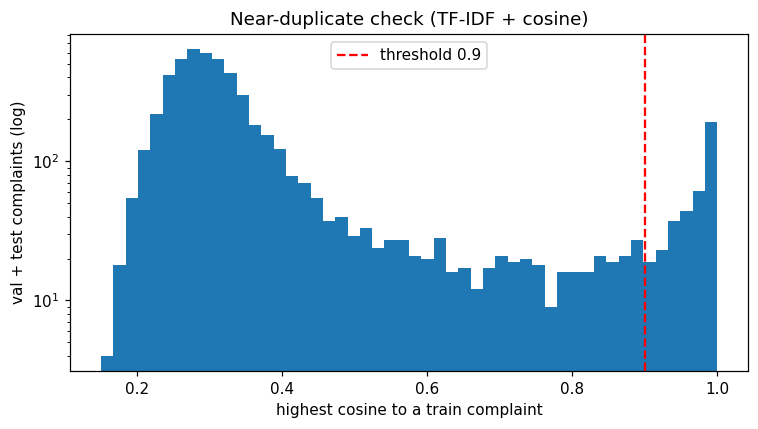

In [27]:
# 1.5 Near-duplicate check (Lecture 3: TF-IDF vectors + cosine similarity)
# Exact duplicates are already removed. Template letters with small edits are NOT exact copies,
# so we look for val/test complaints whose TF-IDF vector is almost identical to a TRAIN complaint.
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

THRESH = 0.90                                            # cosine >= 0.90 = near-duplicate
vec = TfidfVectorizer(sublinear_tf=True, min_df=2)
X_tr = vec.fit_transform(splits["train"]["text"])        # fitted on TRAIN only (no leakage)

def max_cosine_to_train(texts, batch=500):
    """For each text: highest cosine to any train complaint, and which one (rows are L2-normalised, so dot = cosine)."""
    X = vec.transform(texts)
    best, nn = np.zeros(X.shape[0]), np.zeros(X.shape[0], dtype=int)
    for s in range(0, X.shape[0], batch):
        S = linear_kernel(X[s:s + batch], X_tr)
        best[s:s + batch], nn[s:s + batch] = S.max(axis=1), S.argmax(axis=1)
    return best, nn

out = RES / "data"; out.mkdir(parents=True, exist_ok=True)
rows, sims = [], {}
train_reset = splits["train"].reset_index(drop=True)
for name in ("val", "test"):
    df = splits[name].reset_index(drop=True)
    sim, nn = max_cosine_to_train(df["text"])
    sims[name] = sim
    near = sim >= THRESH
    print(f"{name}: {near.sum()} of {len(df)} complaints ({near.mean():.1%}) have a near-duplicate in train")
    for p, n in df.loc[near, "product"].value_counts().items():
        rows.append({"split": name, "product": p, "near_duplicates": n})
    if near.any():                                       # show one example pair
        i = int(np.argmax(np.where(sim < 0.999, sim, 0)))  # most similar pair that is NOT identical
        print(f"  example, cosine {sim[i]:.3f}\n   {name.upper()}: {df.loc[i, 'text'][:250]}...\n"
              f"   TRAIN: {train_reset.loc[nn[i], 'text'][:250]}...\n")
    splits[name] = df[~near]                             # remove them: they would inflate test scores

pd.DataFrame(rows).to_csv(out / "near_duplicates.csv", index=False)
for name, df in splits.items():                          # save the cleaned splits for the next cells
    df.to_csv(CONFIG["paths"]["processed_dir"] / f"{name}.csv", index=False)
print(f"after cleaning: train={len(splits['train']):,}  val={len(splits['val']):,}  test={len(splits['test']):,}")

plt.figure(figsize=(7, 4))
plt.hist(np.concatenate(list(sims.values())), bins=50)
plt.axvline(THRESH, color="red", ls="--", label=f"threshold {THRESH}")
plt.yscale("log"); plt.xlabel("highest cosine to a train complaint"); plt.ylabel("val + test complaints (log)")
plt.title("Near-duplicate check (TF-IDF + cosine)"); plt.legend(); plt.tight_layout()
plt.savefig(out / "near_duplicates_hist.png", dpi=150); plt.show()

In [15]:
import pandas as pd
all_data = pd.concat(splits.values())
print(all_data["product"].value_counts())
print("\nDuplicate texts removed:", 5 * CONFIG["data"]["per_class"] - len(all_data))

product
Checking or savings account    4000
Mortgage                       3998
Credit card                    3579
Debt collection                3369
Credit reporting               3313
Name: count, dtype: int64

Duplicate texts removed: 1741


In [14]:
pd.read_csv(RES / "data/product_counts_raw.csv").head(12)

,product_raw,n
0,Credit reporting or other personal consumer reports,715618
1,"Credit reporting, credit repair services, or other personal consumer reports",216716
2,Debt collection,99625
3,Checking or savings account,55503
4,Credit card,47105
5,Mortgage,24762
6,Credit card or prepaid card,20575
7,"Money transfer, virtual currency, or money service",18358
8,Vehicle loan or lease,14351
9,Student loan,13957


## 2. Pre-processing, adapted to each model (Lecture 2)

There is no universal pipeline: every operation removes information, so we choose per model.

| Input | Operations | Why |
|---|---|---|
| **All models** (`text_clean`) | Remove CFPB redaction masks (`XXXX`, `XX/XX/2023`, `{$100.00}`), collapse whitespace | The masks are privacy artefacts, not language; they would become frequent fake "words" |
| **TF-IDF and LDA** (`text_sparse`) | Lowercase, alphabetic tokens, stopword removal **keeping negations** (not, no, never), WordNet lemmatization | Sparse models need a compact vocabulary; "not" carries meaning in complaints |
| **Sentence embeddings** (`text_clean`) | Nothing else | Transformers have their own sub-word tokenizer and need function words and word order |

In [16]:
REDACTION = re.compile(r"\{\$[\d.,]+\}|\b(?:XX/){1,2}(?:XX|\d{2,4})\b|\bX{2,}\b", flags=re.IGNORECASE)
TOKEN = re.compile(r"[a-z]+")
NEGATIONS = {"not", "no", "nor", "never", "cannot"}
P = CONFIG["preprocess"]
STOPWORDS = frozenset(ENGLISH_STOP_WORDS - NEGATIONS) if P["keep_negations"] else frozenset(ENGLISH_STOP_WORDS)

def get_lemmatizer():
    try:
        import nltk
        from nltk.stem import WordNetLemmatizer
        try:
            nltk.data.find("corpora/wordnet")
        except LookupError:
            nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)
        lem = WordNetLemmatizer(); lem.lemmatize("tests")
        return lem
    except Exception as exc:
        print("WordNet lemmatizer unavailable, continuing without lemmatization:", exc)
        return None

LEMMATIZER = get_lemmatizer() if P["lemmatize"] else None

def clean_raw(text):
    text = str(text)
    if P["remove_redactions"]:
        text = REDACTION.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

def for_sparse(text):
    tokens = [t for t in TOKEN.findall(text.lower()) if len(t) > 1 and t not in STOPWORDS]
    if LEMMATIZER is not None:
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

for name, df in splits.items():
    df["text_clean"] = df["text"].map(clean_raw)
    df["text_sparse"] = df["text_clean"].map(for_sparse)

example = splits["train"].iloc[0]
print("RAW   :", example["text"][:300], "\n")
print("CLEAN :", example["text_clean"][:300], "\n")
print("SPARSE:", example["text_sparse"][:300])

RAW   : Synchrony bank closed my account without notice and without a legitimate reason and forced a forfeiture on the rewards I accumulated over the years. I had a 100 % payment history and acted in good faith. 

CLEAN : Synchrony bank closed my account without notice and without a legitimate reason and forced a forfeiture on the rewards I accumulated over the years. I had a 100 % payment history and acted in good faith. 

SPARSE: synchrony bank closed account notice legitimate reason forced forfeiture reward accumulated year payment history acted good faith


## 3. Exploratory analysis

Class balance per split, complaint length, the **Zipf plot** of the training vocabulary (Lecture 2: few very frequent words, a long tail of rare ones), and the most frequent words per product.

,train,val,test
product,,,
Checking or savings account,2800,600,600
Mortgage,2799,600,599
Credit card,2505,537,537
Debt collection,2358,505,506
Credit reporting,2319,497,497


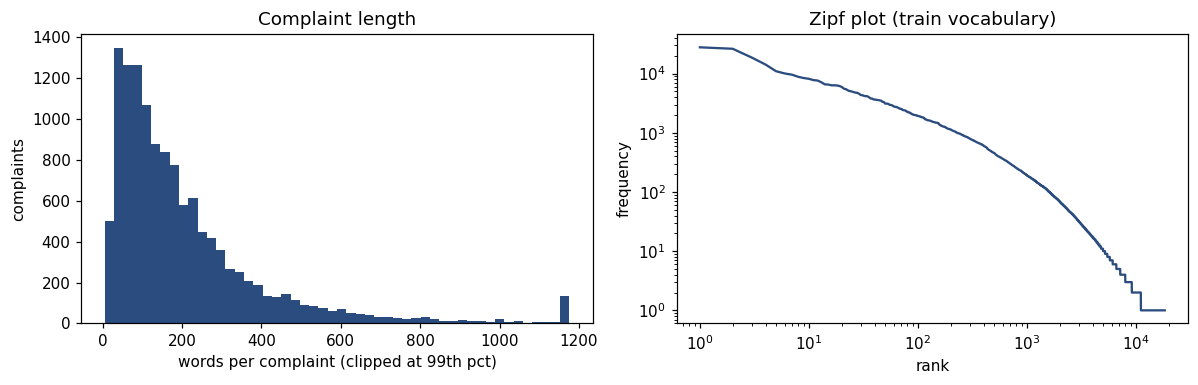

{'length_mean': 215.05899381895, 'length_median': 148.0, 'vocabulary_size': 18360, 'hapax_share': 0.3968954248366013}


,Checking or savings account,Credit card,Credit reporting,Debt collection,Mortgage
0,account,card,credit,debt,payment
1,not,credit,account,credit,not
2,bank,not,report,not,mortgage
3,money,account,consumer,account,loan
4,check,payment,information,report,account
5,no,charge,not,collection,time
6,fund,bank,reporting,information,no
7,day,time,section,consumer,home
8,told,no,agency,company,received
9,transaction,did,payment,reporting,company


In [17]:
train, val, test = splits["train"], splits["val"], splits["test"]
display(pd.DataFrame({s: df["product"].value_counts() for s, df in splits.items()}))

lengths = train["text_clean"].str.split().str.len()
freq = Counter(w for t in train["text_sparse"] for w in t.split())
f = np.array(sorted(freq.values(), reverse=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(lengths.clip(upper=lengths.quantile(0.99)), bins=50, color="#2b4c7e")
ax[0].set(xlabel="words per complaint (clipped at 99th pct)", ylabel="complaints", title="Complaint length")
ax[1].loglog(np.arange(1, len(f) + 1), f, color="#2b4c7e")
ax[1].set(xlabel="rank", ylabel="frequency", title="Zipf plot (train vocabulary)")
savefig(fig, "eda_length_zipf.png")

stats = {"length_mean": float(lengths.mean()), "length_median": float(lengths.median()),
         "vocabulary_size": len(freq), "hapax_share": sum(v == 1 for v in freq.values()) / len(freq)}
save_json(stats, RES / "explore/stats.json"); print(stats)

top_words = {p: [w for w, _ in Counter(w for t in g["text_sparse"] for w in t.split()).most_common(12)]
             for p, g in train.groupby("product")}
pd.DataFrame(top_words)

## 4. Task 1: Complaint routing (text classification)

**Protocol (no leakage):** fit on **train**, choose the regularisation strength $C$ on **validation** (macro-F1), evaluate **once on test**.

| | Representation (Lecture 3) | Classifier |
|---|---|---|
| **Baseline** | TF-IDF, uni+bigrams, sublinear TF, vocabulary and IDF learned on train only | Logistic Regression |
| **Alternative** | Sentence embeddings (`all-MiniLM-L6-v2`, 384 dimensions) | Logistic Regression |
| Optional | none: zero-shot natural-language-inference model | none (no training data) |

**Main metric: macro-F1**, the average F1 over products, so that every product counts equally. We also report accuracy, a 95% bootstrap confidence interval, confusion matrices and misclassified examples.

In [18]:
LABELS = sorted(train["product"].unique())
C = CONFIG["classification"]

def tune_logreg(X_tr, y_tr, X_va, y_va):
    best = (None, -1, None)
    for c in C["C_grid"]:
        m = LogisticRegression(C=c, max_iter=3000, random_state=CONFIG["seed"]).fit(X_tr, y_tr)
        s = f1_score(y_va, m.predict(X_va), average="macro")
        print(f"  C={c:<5} validation macro-F1 = {s:.4f}")
        if s > best[1]:
            best = (c, s, m)
    return best

def bootstrap_ci(y_true, y_pred, n=1000):
    rng = np.random.default_rng(CONFIG["seed"])
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = [f1_score(y_true[i], y_pred[i], average="macro", labels=LABELS)
              for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return tuple(np.percentile(scores, [2.5, 97.5]).round(4))

def plot_confusion(y_true, y_pred, title, name):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    short = [l if len(l) <= 22 else l[:20] + "…" for l in LABELS]
    ax.set_xticks(range(len(LABELS)), short, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(LABELS)), short, fontsize=8)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set(xlabel="Predicted product", ylabel="True product", title=title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    savefig(fig, name)

RESULTS = {}
def evaluate(name, model, X_te, extra):
    t0 = time.perf_counter(); pred = model.predict(X_te); infer = time.perf_counter() - t0
    RESULTS[name] = {"accuracy": accuracy_score(test["product"], pred),
                     "macro_f1": f1_score(test["product"], pred, average="macro"),
                     "macro_f1_95ci": bootstrap_ci(test["product"], pred),
                     "inference_s": infer, **extra}
    print(classification_report(test["product"], pred, digits=3, zero_division=0))
    plot_confusion(test["product"], pred, f"Confusion matrix: {name}", f"confusion_{name}.png")
    errors = test.assign(predicted=pred).query("predicted != product")
    errors[["complaint_id", "product", "predicted", "issue", "text_clean"]].head(100).to_csv(
        RES / f"classification_errors_{name}.csv", index=False)
    return pred

### 4.1 Baseline: TF-IDF + Logistic Regression

  C=0.1   validation macro-F1 = 0.8388
  C=1.0   validation macro-F1 = 0.8643
  C=10.0  validation macro-F1 = 0.8652
                             precision    recall  f1-score   support

Checking or savings account      0.870     0.938     0.903       600
                Credit card      0.857     0.823     0.840       537
           Credit reporting      0.818     0.843     0.831       497
            Debt collection      0.855     0.794     0.824       506
                   Mortgage      0.956     0.948     0.952       599

                   accuracy                          0.874      2739
                  macro avg      0.871     0.869     0.870      2739
               weighted avg      0.874     0.874     0.874      2739



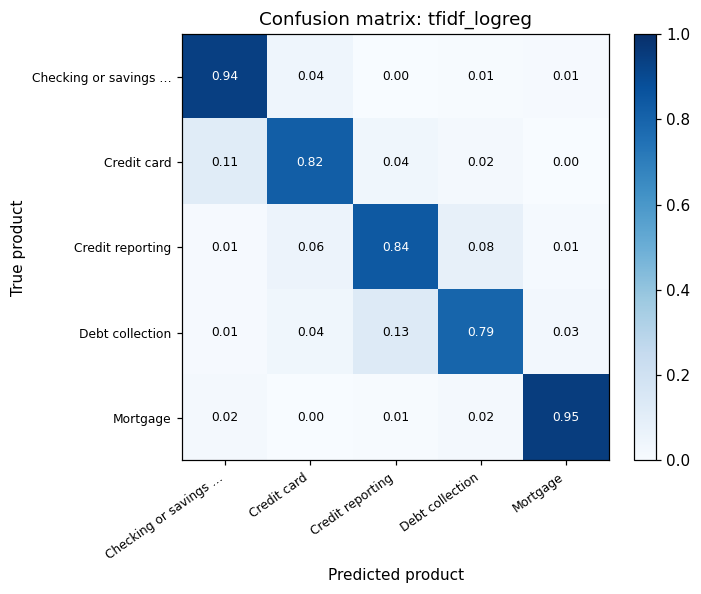

,Checking or savings account,Credit card,Credit reporting,Debt collection,Mortgage
0,bank,card,experian,debt,mortgage
1,account,credit card,transunion,collection,loan
2,fund,capital,report,collect,home
3,deposit,synchrony,equifax,owe,escrow
4,chime,charge,inquiry,collector,payment
5,money,comenity,credit,owed,property
6,transaction,amex,credit report,time day,foreclosure
7,saving,american express,reporting,credit management,heloc
8,checking,billing,balance balance,company,house
9,debit,credit,credit bureau,credit,modification


In [19]:
t0 = time.perf_counter()
tfidf = TfidfVectorizer(**C["tfidf"])
X_tr = tfidf.fit_transform(train["text_sparse"])          # vocabulary + IDF from TRAIN only
X_va, X_te = tfidf.transform(val["text_sparse"]), tfidf.transform(test["text_sparse"])
best_C, val_f1, lr_tfidf = tune_logreg(X_tr, train["product"], X_va, val["product"])
pred_tfidf = evaluate("tfidf_logreg", lr_tfidf, X_te,
                      {"best_C": best_C, "val_macro_f1": val_f1, "n_features": X_tr.shape[1],
                       "train_s": time.perf_counter() - t0})

# interpretability: the words that push a complaint towards each product
feats = np.array(tfidf.get_feature_names_out())
top_feats = pd.DataFrame({lab: feats[np.argsort(lr_tfidf.coef_[i])[-12:][::-1]]
                          for i, lab in enumerate(lr_tfidf.classes_)})
top_feats.to_csv(RES / "tfidf_top_features.csv", index=False)
top_feats

### 4.2 Alternative: sentence embeddings + Logistic Regression

The first run downloads the model (~90 MB) and encodes about 20,000 texts: several minutes on a CPU. The embeddings are **cached** in `data/processed/cache/`, so later runs are instant. They are reused in Task 2.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/43 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/43 [00:00<?, ?it/s]

  C=0.1   validation macro-F1 = 0.8335
  C=1.0   validation macro-F1 = 0.8419
  C=10.0  validation macro-F1 = 0.8435
                             precision    recall  f1-score   support

Checking or savings account      0.866     0.895     0.880       600
                Credit card      0.803     0.799     0.801       537
           Credit reporting      0.776     0.837     0.805       497
            Debt collection      0.816     0.729     0.770       506
                   Mortgage      0.940     0.937     0.938       599

                   accuracy                          0.844      2739
                  macro avg      0.840     0.839     0.839      2739
               weighted avg      0.844     0.844     0.844      2739



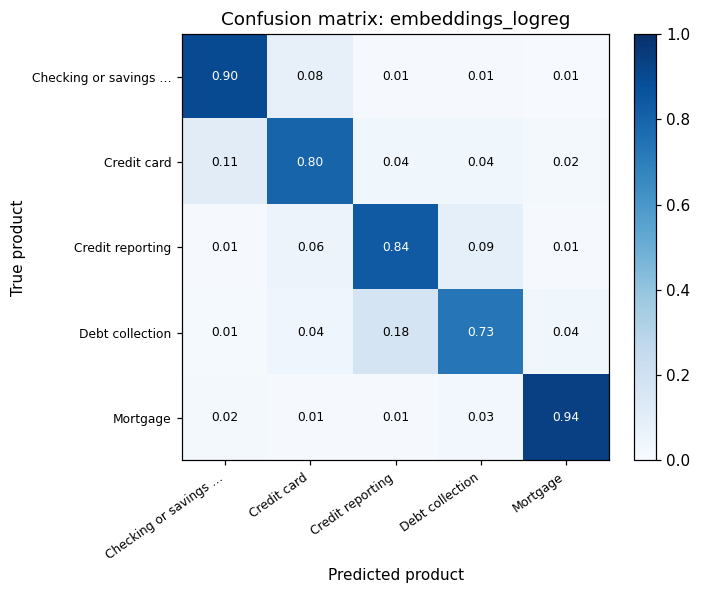

In [20]:
def embed(texts, name):
    cache = CONFIG["paths"]["cache_dir"] / f"emb_{C['embedding_model'].split('/')[-1]}_{name}.npy"
    cache.parent.mkdir(parents=True, exist_ok=True)
    if cache.exists():
        return np.load(cache)
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(C["embedding_model"])
    emb = model.encode(list(texts), batch_size=C["batch_size"], show_progress_bar=True, normalize_embeddings=True)
    np.save(cache, emb)
    return emb

USE_EMB = C["use_embeddings"]
if USE_EMB:
    t0 = time.perf_counter()
    E_tr, E_va, E_te = embed(train["text_clean"], "train"), embed(val["text_clean"], "val"), embed(test["text_clean"], "test")
    best_C_e, val_f1_e, lr_emb = tune_logreg(E_tr, train["product"], E_va, val["product"])
    pred_emb = evaluate("embeddings_logreg", lr_emb, E_te,
                        {"best_C": best_C_e, "val_macro_f1": val_f1_e, "n_features": E_tr.shape[1],
                         "train_s_incl_encoding": time.perf_counter() - t0})

### 4.3 Optional: zero-shot classification (no training data)

A pretrained natural-language-inference model is asked which product name best fits each complaint. Set `CONFIG["classification"]["zeroshot"]["enabled"] = True` to run it on 500 stratified test complaints. It downloads about 1.6 GB and is slow on a CPU. It shows what a "no labels" model can do, and at what cost.

In [21]:
Z = C["zeroshot"]
if Z["enabled"]:
    from transformers import pipeline
    sample = test.groupby("product", group_keys=False).apply(
        lambda g: g.sample(n=min(len(g), Z["n_samples"] // len(LABELS)), random_state=CONFIG["seed"]))
    clf = pipeline("zero-shot-classification", model=Z["model"])
    t0 = time.perf_counter()
    z_pred = [clf(t[:2000], candidate_labels=LABELS)["labels"][0] for t in sample["text_clean"]]
    RESULTS["zeroshot"] = {"accuracy": accuracy_score(sample["product"], z_pred),
                           "macro_f1": f1_score(sample["product"], z_pred, average="macro"),
                           "n_samples": len(sample), "inference_s": time.perf_counter() - t0}
    print(RESULTS["zeroshot"])

### 4.4 Comparison

In [22]:
comparison = pd.DataFrame({k: {m: v.get(m) for m in ("accuracy", "macro_f1", "macro_f1_95ci", "inference_s")}
                           for k, v in RESULTS.items()}).T
comparison.to_csv(RES / "classification_comparison.csv"); save_json(RESULTS, RES / "classification_metrics.json")
comparison

,accuracy,macro_f1,macro_f1_95ci,inference_s
tfidf_logreg,0.874042,0.869798,"(0.8573, 0.8824)",0.005521
embeddings_logreg,0.844104,0.83907,"(0.8258, 0.8528)",0.006774


## 5. Task 2: Complaint themes (topic modeling)

| | Input | Model |
|---|---|---|
| **Baseline** | Bag-of-words counts | **LDA** (probabilistic topic model) |
| **Alternative** | Sentence embeddings | **Embedding topics** (the BERTopic idea): K-Means clusters of embeddings + **class-based TF-IDF** keywords per cluster |

**Protocol:**

- Models are fitted on **train**.
- The number of topics $k$ is chosen by **topic coherence**, computed on **validation** texts: C_v with gensim, or NPMI if gensim is not installed.
- We also report **topic diversity** (how many top words are unique) and **NMI/ARI on test** against the product labels. This is an external check: do the discovered themes relate to the products?

Class-based TF-IDF (Grootendorst, 2022): $W_{t,c} = \mathrm{tf}_{t,c} \cdot \log\left(1 + \frac{A}{f_t}\right)$, where $\mathrm{tf}_{t,c}$ is the frequency of word $t$ in cluster $c$, $A$ the average number of words per cluster, and $f_t$ the frequency of $t$ over all clusters.

In [23]:
T = CONFIG["topics"]
try:
    from gensim.corpora import Dictionary
    from gensim.models.coherencemodel import CoherenceModel
    COH = "C_v"
except ImportError:
    COH = "NPMI"
print("Coherence measure:", COH)

ref_texts = [s.split() for s in val["text_sparse"]]           # held-out reference texts
dictionary = Dictionary(ref_texts) if COH == "C_v" else None

def npmi(topics, eps=1e-12):
    docs = [set(t) for t in ref_texts]; n = len(docs); cache = {}
    def p(*w):
        k = tuple(sorted(w))
        if k not in cache:
            cache[k] = sum(all(x in d for x in w) for d in docs) / n
        return cache[k]
    s = [(-1.0 if p(a, b) == 0 else np.log(p(a, b) / (p(a) * p(b))) / -np.log(p(a, b) + eps))
         for t in topics for a, b in combinations(t, 2) if p(a) > 0 and p(b) > 0]
    return float(np.mean(s)) if s else float("nan")

def coherence(topics):
    if COH == "NPMI":
        return npmi(topics)
    topics = [[w for w in t if w in dictionary.token2id] for t in topics]
    return CoherenceModel(topics=[t for t in topics if len(t) > 1], texts=ref_texts,
                          dictionary=dictionary, coherence="c_v", processes=1).get_coherence()

def top_words(weights, vocab, n=T["n_top_words"]):
    return [list(vocab[np.argsort(r)[-n:][::-1]]) for r in weights]

def diversity(topics):
    w = [x for t in topics for x in t]; return len(set(w)) / len(w)

def ctfidf(counts, labels, k):
    tf = np.vstack([np.asarray(counts[labels == c].sum(axis=0)).ravel() for c in range(k)])
    A, f = tf.sum() / k, tf.sum(axis=0) + 1e-12
    return (tf / (tf.sum(axis=1, keepdims=True) + 1e-12)) * np.log(1 + A / f)

cv = CountVectorizer(min_df=5, max_df=0.5)
C_tr, C_te = cv.fit_transform(train["text_sparse"]), cv.transform(test["text_sparse"])
vocab = cv.get_feature_names_out()

rows, best = [], {}
for k in T["k_grid"]:
    lda = LatentDirichletAllocation(n_components=k, max_iter=T["lda_max_iter"], random_state=CONFIG["seed"]).fit(C_tr)
    candidates = {"LDA": (top_words(lda.components_, vocab), lda.transform(C_te).argmax(axis=1))}
    if T["use_embeddings"] and USE_EMB:
        km = KMeans(n_clusters=k, n_init=10, random_state=CONFIG["seed"]).fit(E_tr)
        candidates["Embedding topics"] = (top_words(ctfidf(C_tr, km.labels_, k), vocab), km.predict(E_te))
    for model, (topics, test_assign) in candidates.items():
        r = {"model": model, "k": k, f"coherence_{COH}": coherence(topics), "diversity": diversity(topics),
             "NMI_test": normalized_mutual_info_score(test["product"], test_assign),
             "ARI_test": adjusted_rand_score(test["product"], test_assign)}
        rows.append(r)
        if r[f"coherence_{COH}"] > best.get(model, (None, -np.inf))[1]:
            best[model] = (k, r[f"coherence_{COH}"], topics)
    print(f"k={k} done")

topic_table = pd.DataFrame(rows)
topic_table.to_csv(RES / "topic_metrics_by_k.csv", index=False)
topic_table.round(3)

Coherence measure: NPMI


C:\Users\lenovo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\lenovo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\lenovo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\lenovo\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^

k=5 done
k=8 done
k=10 done
k=15 done
k=20 done


,model,k,coherence_NPMI,diversity,NMI_test,ARI_test
0,LDA,5,0.200,0.900,0.417,0.404
1,Embedding topics,5,0.210,0.760,0.538,0.531
2,LDA,8,0.209,0.862,0.373,0.326
3,Embedding topics,8,0.221,0.712,0.494,0.465
4,LDA,10,0.195,0.790,0.373,0.322
5,Embedding topics,10,0.223,0.680,0.466,0.379
6,LDA,15,0.189,0.680,0.330,0.205
7,Embedding topics,15,0.203,0.533,0.425,0.285
8,LDA,20,0.199,0.650,0.310,0.175
9,Embedding topics,20,0.212,0.500,0.402,0.211


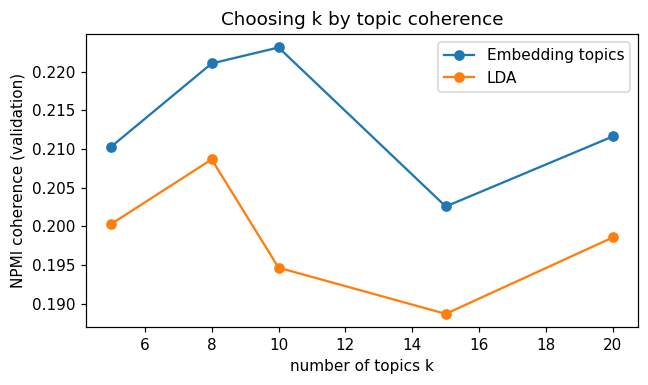


LDA: best k = 8 (NPMI = 0.209)


,topic 0,topic 1,topic 2,topic 3,topic 4,topic 5,topic 6,topic 7
0,credit,loan,received,payment,matter,debt,card,bank
1,report,mortgage,sent,mortgage,financial,collection,credit,check
2,consumer,home,email,late,request,well,charge,money
3,information,property,letter,month,issue,fargo,transaction,fund
4,reporting,modification,told,insurance,action,credit,dispute,day
5,section,foreclosure,called,pay,regarding,creditor,bank,told
6,agency,application,no,paid,despite,original,did,no
7,right,rate,information,escrow,complaint,collector,no,deposit
8,inaccurate,document,phone,fee,provide,alleged,balance,called
9,item,no,did,time,response,company,never,chase



Embedding topics: best k = 10 (NPMI = 0.223)


,topic 0,topic 1,topic 2,topic 3,topic 4,topic 5,topic 6,topic 7,topic 8,topic 9
0,credit,consumer,report,card,card,loan,insurance,debt,payment,bank
1,report,reporting,credit,charge,credit,mortgage,escrow,collection,late,check
2,identity,section,reporting,dispute,fee,payment,tax,credit,credit,fund
3,theft,information,information,transaction,balance,home,mortgage,collector,error,money
4,inquiry,agency,consumer,bank,payment,time,payment,alleged,time,deposit
5,information,right,inaccurate,credit,charge,modification,policy,company,day,told
6,fraudulent,state,fcra,claim,bank,no,paid,creditor,fee,no
7,consumer,privacy,item,fraud,month,told,property,report,report,day
8,remove,usc,reported,did,pay,received,company,validation,date,checking
9,reporting,furnish,bureau,told,charged,month,pay,consumer,never,closed


In [24]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for model, g in topic_table.groupby("model"):
    ax.plot(g["k"], g[f"coherence_{COH}"], "o-", label=model)
ax.set(xlabel="number of topics k", ylabel=f"{COH} coherence (validation)", title="Choosing k by topic coherence")
ax.legend(); savefig(fig, "coherence_by_k.png")

for model, (k, coh, topics) in best.items():
    print(f"\n{model}: best k = {k} ({COH} = {coh:.3f})")
    tw = pd.DataFrame({f"topic {i}": t for i, t in enumerate(topics)})
    tw.to_csv(RES / f"top_words_{model.replace(' ', '_').lower()}_k{k}.csv", index=False)
    display(tw)

## 6. Results summary

The two tables the report needs. All numbers come from this run.

In [25]:
best_rows = topic_table.loc[topic_table.groupby("model")[f"coherence_{COH}"].idxmax()]
print("Task 1: classification (test set)"); display(comparison)
print(f"Task 2: topic modeling (best k by {COH} coherence)"); display(best_rows.round(3))

Task 1: classification (test set)


,accuracy,macro_f1,macro_f1_95ci,inference_s
tfidf_logreg,0.874042,0.869798,"(0.8573, 0.8824)",0.005521
embeddings_logreg,0.844104,0.83907,"(0.8258, 0.8528)",0.006774


Task 2: topic modeling (best k by NPMI coherence)


,model,k,coherence_NPMI,diversity,NMI_test,ARI_test
5,Embedding topics,10,0.223,0.680,0.466,0.379
2,LDA,8,0.209,0.862,0.373,0.326


## 7. Discussion: what to write in the report (fill in after running)

Answer these with the outputs above. The professor grades the **critical discussion**, not only the scores.

1. **Baseline vs alternative (Task 1):**
    - Which representation wins on macro-F1?
    - Do the 95% confidence intervals overlap? If so, the difference may not be meaningful.
    - What does each cost in time (`train_s`, `inference_s`)?
2. **Errors:**
    - Which products are confused (confusion matrices)?
    - Read 10 misclassified complaints in `results/classification_errors_*.csv`: are they model errors, or **noisy labels** (consumers choose the product themselves)?
3. **Interpretability:** do the top TF-IDF words per product make sense (`tfidf_top_features.csv`)?
4. **Topics (Task 2):**
    - Which model gives more coherent and more diverse topics?
    - Name the best topics from their top words.
    - Do themes cut across products (e.g. customer service, fraud)? That explains a low NMI.
5. **Pre-processing:**
    - What did removing redactions and keeping negations change?
    - Optionally rerun with `keep_negations = False` and compare.
6. **Limitations and bias:**
    - balanced sampling, unlike the real distribution;
    - only consented narratives;
    - US, 2023–2024 only;
    - lemmatization without POS tags;
    - a single random split.
7. **Business value:** how would routing plus theme monitoring be used by a complaints team?

## 8. Reproducibility

Library versions of this run (copy them into the README / report).

In [26]:
import importlib, platform
versions = {"python": platform.python_version()}
for lib in ["numpy", "pandas", "sklearn", "gensim", "nltk", "matplotlib", "sentence_transformers", "transformers", "torch"]:
    try:
        versions[lib] = importlib.import_module(lib).__version__
    except Exception:
        versions[lib] = "not installed"
save_json(versions, RES / "versions.json"); versions

{'python': '3.13.5',
 'numpy': '2.1.3',
 'pandas': '2.2.3',
 'sklearn': '1.6.1',
 'gensim': 'not installed',
 'nltk': '3.9.1',
 'matplotlib': '3.10.7',
 'sentence_transformers': '5.5.0',
 'transformers': '5.8.1',
 'torch': '2.12.0+cpu'}